# ow-0008 (June 2019) -- supplementary trajectory/heatmap/AIS visuals

**Parity fill-in, same unmodified code as ow-0008's own equivalents.** ow-0008's
`output/ow-0008/` folder has 5 files that predate the `production_run_*` notebook
convention (`04_hotspot_heatmap.png`, `07_multimember_static.png`,
`08_multimember_animation.mp4`, `AIS_tracks_map.png`, `validation_map_alignment.png`
-- originally from `main_june2019_full_pipeline.ipynb`/`AIS2_track_validation.ipynb`).
This notebook reproduces the SAME 5 artifacts for ow-0008, using the exact same
plotting code, applied to ow-0008's own already-computed Stage III/AIS data. Saved
directly to `output/ow-0008/` (not `result_june2019/`), per explicit instruction.

In [1]:
import os, sys, json as _json, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import PowerNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from iste.ensemble_run import EnsembleRunRecords
from iste.particle_query import query_particle_slice
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.candidate_extraction import CandidateExtractionConfig, find_candidate_peaks

RESULT_DIR = os.path.join(REPO_ROOT, "result")   # existing artifacts (read-only)
OUTPUT_DIR = os.path.join(REPO_ROOT, "output", "ow-0008")  # this notebook's only write target
os.makedirs(OUTPUT_DIR, exist_ok=True)

def save_with_retry(save_callable, label="", retries=8, delay=2.0):
    last_err = None
    for attempt in range(retries):
        try:
            save_callable()
            return
        except OSError as e:
            last_err = e
            print(f"  [retry {attempt + 1}/{retries}] transient save error for {label}: {e}")
            time.sleep(delay)
    raise last_err

def save_animation_with_retry(anim, mp4_path, gif_path, fps, retries=8, delay=2.0):
    last_err = None
    for attempt in range(retries):
        try:
            anim.save(mp4_path, writer="ffmpeg", fps=fps, dpi=100)
            print(f"saved animation (MP4) to {mp4_path}")
            return
        except OSError as e:
            last_err = e
            print(f"  [retry {attempt + 1}/{retries}] transient save error for {mp4_path}: {e}")
            time.sleep(delay)
        except Exception as e:
            anim.save(gif_path, writer="pillow", fps=fps)
            print(f"ffmpeg unavailable ({e}); saved GIF to {gif_path}")
            return
    anim.save(gif_path, writer="pillow", fps=fps)
    print(f"MP4 save kept failing transiently ({last_err}); saved GIF to {gif_path} instead")

## 1. Load Stage III particle history + observation (ow-0008, already computed)

In [2]:
history_path = os.path.join(RESULT_DIR, "stage3_particle_history_june2019.npz")
cached = np.load(history_path, allow_pickle=True)
def _none_if_empty(arr):
    return None if arr.size == 0 else arr
records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
T_OBS = np.datetime64(np.max(records.timestamp), "ns")
checkpoints = np.unique(records.timestamp)  # ascending -> [0]=T72 (oldest), [-1]=T0
print(f"loaded {records.n_records} ow-0008 rows; {len(checkpoints)} checkpoints; T_OBS={T_OBS}")

spill_data = _json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
obs_bbox = spill["bounding_box"]
parcels = spill["parcels"]
obs_lat = np.array([p["lat"] for p in parcels]); obs_lon = np.array([p["lon"] for p in parcels])

loaded 240024 ow-0008 rows; 73 checkpoints; T_OBS=2019-06-14T20:35:58.000000000


## 2. Geographic basemap helper + trajectory-zoomed extent (Task 2/3 conventions, unchanged)

In [3]:
AOI_NORTH, AOI_WEST, AOI_SOUTH, AOI_EAST = 36.372, 27.121, 30.1875, 36.088  # project AOI (reference)
MAP_PROJECTION = ccrs.PlateCarree()

TRAJ_LAT_MIN = float(records.lat[records.valid].min())
TRAJ_LAT_MAX = float(records.lat[records.valid].max())
TRAJ_LON_MIN = float(records.lon[records.valid].min())
TRAJ_LON_MAX = float(records.lon[records.valid].max())
print(f"complete backtracked-trajectory bbox: lat [{TRAJ_LAT_MIN:.5f}, {TRAJ_LAT_MAX:.5f}], "
      f"lon [{TRAJ_LON_MIN:.5f}, {TRAJ_LON_MAX:.5f}]")

TRAJECTORY_MAP_MARGIN_DEG = 0.08  # explicit, configurable -- same margin already approved (Task 3)
ZOOM_WEST = TRAJ_LON_MIN - TRAJECTORY_MAP_MARGIN_DEG
ZOOM_EAST = TRAJ_LON_MAX + TRAJECTORY_MAP_MARGIN_DEG
ZOOM_SOUTH = TRAJ_LAT_MIN - TRAJECTORY_MAP_MARGIN_DEG
ZOOM_NORTH = TRAJ_LAT_MAX + TRAJECTORY_MAP_MARGIN_DEG
ANIMATION_EXTENT = (ZOOM_WEST, ZOOM_EAST, ZOOM_SOUTH, ZOOM_NORTH)
print(f"animation map extent (trajectory bbox + {TRAJECTORY_MAP_MARGIN_DEG}deg margin): "
      f"lon [{ZOOM_WEST:.4f}, {ZOOM_EAST:.4f}], lat [{ZOOM_SOUTH:.4f}, {ZOOM_NORTH:.4f}]")

_land_10m = cfeature.NaturalEarthFeature("physical", "land", "10m", facecolor="#e8dcc8")
_ocean_10m = cfeature.NaturalEarthFeature("physical", "ocean", "10m", facecolor="#cfe8f3")

def add_geographic_basemap(ax, extent):
    west, east, south, north = extent
    ax.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    ax.add_feature(_ocean_10m, zorder=0)
    ax.add_feature(_land_10m, zorder=1)
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.8, zorder=2)
    ax.add_feature(cfeature.BORDERS.with_scale("10m"), linewidth=0.5, linestyle=":", zorder=2)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.6, linestyle="--")
    gl.top_labels = False; gl.right_labels = False
    gl.xlabel_style = {"size": 7}; gl.ylabel_style = {"size": 7}
    return ax

complete backtracked-trajectory bbox: lat [34.06498, 34.43411], lon [34.91946, 35.32912]
animation map extent (trajectory bbox + 0.08deg margin): lon [34.8395, 35.4091], lat [33.9850, 34.5141]


## 3. T14-T17 candidate sweep (needed for the hotspot-heatmap snapshot panel; same code as production run)

In [4]:
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)
historical_timestamps = checkpoints[checkpoints != T_OBS]

t0 = time.time()
all_candidates = []
support_grids_by_t_s = {}
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config)
    support_grids_by_t_s[float(t_s)] = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    all_candidates.extend(find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config))

_t0_slice = query_particle_slice(records, T_OBS)
_t0_index = build_particle_neighborhood_index(_t0_slice)
_t0_support_map = compute_support_map(_t0_index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config)
support_grids_by_t_s[float(T_OBS)] = np.array([sf.support for sf in _t0_support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
t1 = time.time()
print(f"T14-T17 sweep over {len(historical_timestamps)} historical timestamps + T0 took {t1 - t0:.1f}s -- "
      f"{len(all_candidates)} candidates, {len(support_grids_by_t_s)} support grids (T0..T72)")

DISPLAY_GAMMA = 0.4  # already-approved (Task 4)
GLOBAL_SUPPORT_VMAX = max(float(g.max()) for g in support_grids_by_t_s.values())
def display_norm():
    return PowerNorm(gamma=DISPLAY_GAMMA, vmin=0.0, vmax=GLOBAL_SUPPORT_VMAX)
DISPLAY_NORM_COLORBAR_LABEL = f"Display-normalized Support (PowerNorm gamma={DISPLAY_GAMMA}, shared fixed vmax across all panels)"

T14-T17 sweep over 72 historical timestamps + T0 took 84.4s -- 271 candidates, 73 support grids (T0..T72)


## 4. `validation_map_alignment.png` (Task 3 validation, unchanged)

project AOI (reference)   : N=36.372, W=27.121, S=30.1875, E=36.088
animation map extent (zoom): west=34.8395 east=35.4091 south=33.9850 north=34.5141
trajectory bbox            : lon [34.9195,35.3291]  lat [34.0650,34.4341]
no trajectory clipped (lon): True
no trajectory clipped (lat): True
trajectory occupies 71.9% of frame width, 69.8% of frame height


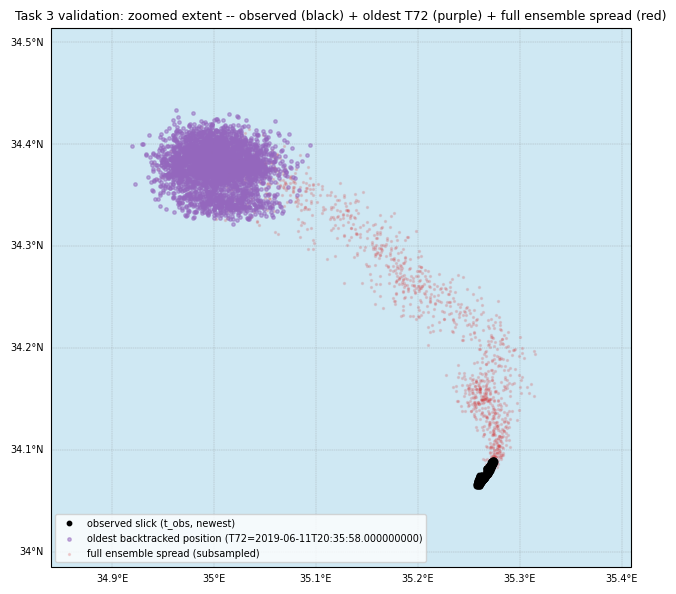

In [5]:
print(f"project AOI (reference)   : N={AOI_NORTH}, W={AOI_WEST}, S={AOI_SOUTH}, E={AOI_EAST}")
print(f"animation map extent (zoom): west={ZOOM_WEST:.4f} east={ZOOM_EAST:.4f} south={ZOOM_SOUTH:.4f} north={ZOOM_NORTH:.4f}")
print(f"trajectory bbox            : lon [{TRAJ_LON_MIN:.4f},{TRAJ_LON_MAX:.4f}]  lat [{TRAJ_LAT_MIN:.4f},{TRAJ_LAT_MAX:.4f}]")

no_clip_lon = (TRAJ_LON_MIN >= ZOOM_WEST) and (TRAJ_LON_MAX <= ZOOM_EAST)
no_clip_lat = (TRAJ_LAT_MIN >= ZOOM_SOUTH) and (TRAJ_LAT_MAX <= ZOOM_NORTH)
print(f"no trajectory clipped (lon): {no_clip_lon}")
print(f"no trajectory clipped (lat): {no_clip_lat}")
assert no_clip_lon and no_clip_lat, "trajectory bbox exceeds the computed zoom extent -- margin too small!"

traj_frac_of_frame_lon = (TRAJ_LON_MAX - TRAJ_LON_MIN) / (ZOOM_EAST - ZOOM_WEST)
traj_frac_of_frame_lat = (TRAJ_LAT_MAX - TRAJ_LAT_MIN) / (ZOOM_NORTH - ZOOM_SOUTH)
print(f"trajectory occupies {traj_frac_of_frame_lon:.1%} of frame width, {traj_frac_of_frame_lat:.1%} of frame height")

fig, ax = plt.subplots(figsize=(8, 7), subplot_kw={"projection": MAP_PROJECTION})
add_geographic_basemap(ax, ANIMATION_EXTENT)
ax.scatter(obs_lon, obs_lat, s=10, c="black", transform=ccrs.PlateCarree(), zorder=6, label="observed slick (t_obs, newest)")
oldest_t = checkpoints[0]
oldest_mask = records.timestamp == oldest_t
oldest_valid = oldest_mask & records.valid
ax.scatter(records.lon[oldest_valid], records.lat[oldest_valid], s=6, c="tab:purple", alpha=0.5, transform=ccrs.PlateCarree(), zorder=5, label=f"oldest backtracked position (T72={oldest_t})")
ax.scatter(records.lon[records.valid][::200], records.lat[records.valid][::200], s=2, alpha=0.15, c="tab:red", transform=ccrs.PlateCarree(), zorder=4, label="full ensemble spread (subsampled)")
ax.legend(fontsize=7, loc="lower left")
ax.set_title("Task 3 validation: zoomed extent -- observed (black) + oldest T72 (purple) + full ensemble spread (red)", fontsize=9)
save_with_retry(lambda: fig.savefig(os.path.join(OUTPUT_DIR, "validation_map_alignment.png"), dpi=100), label="validation_map_alignment.png")
plt.show()

## 5. Select 10 real particles (same deterministic seed) + member-0 trajectories

In [6]:
unique_particle_ids = sorted(set(records.particle_id.tolist()), key=lambda x: int(x))
rng = np.random.default_rng(2024)
n_select = min(10, len(unique_particle_ids))
selected_10 = sorted(rng.choice(unique_particle_ids, size=n_select, replace=False).tolist(), key=int)
print(f"{n_select} deterministically-selected real particle_ids: {selected_10}")

member0_mask = records.forcing_member_id == 0
traj = {}
for pid in selected_10:
    mask = (records.particle_id == pid) & member0_mask
    order = np.argsort(-records.timestamp[mask].astype("int64"))
    traj[pid] = dict(lat=records.lat[mask][order], lon=records.lon[mask][order], t=records.timestamp[mask][order])
colors = plt.cm.tab10(np.linspace(0, 1, n_select))

10 deterministically-selected real particle_ids: ['49', '116', '130', '168', '172', '364', '436', '495', '500', '545']


## 6. `07_multimember_static.png` (6 forcing members, unchanged)

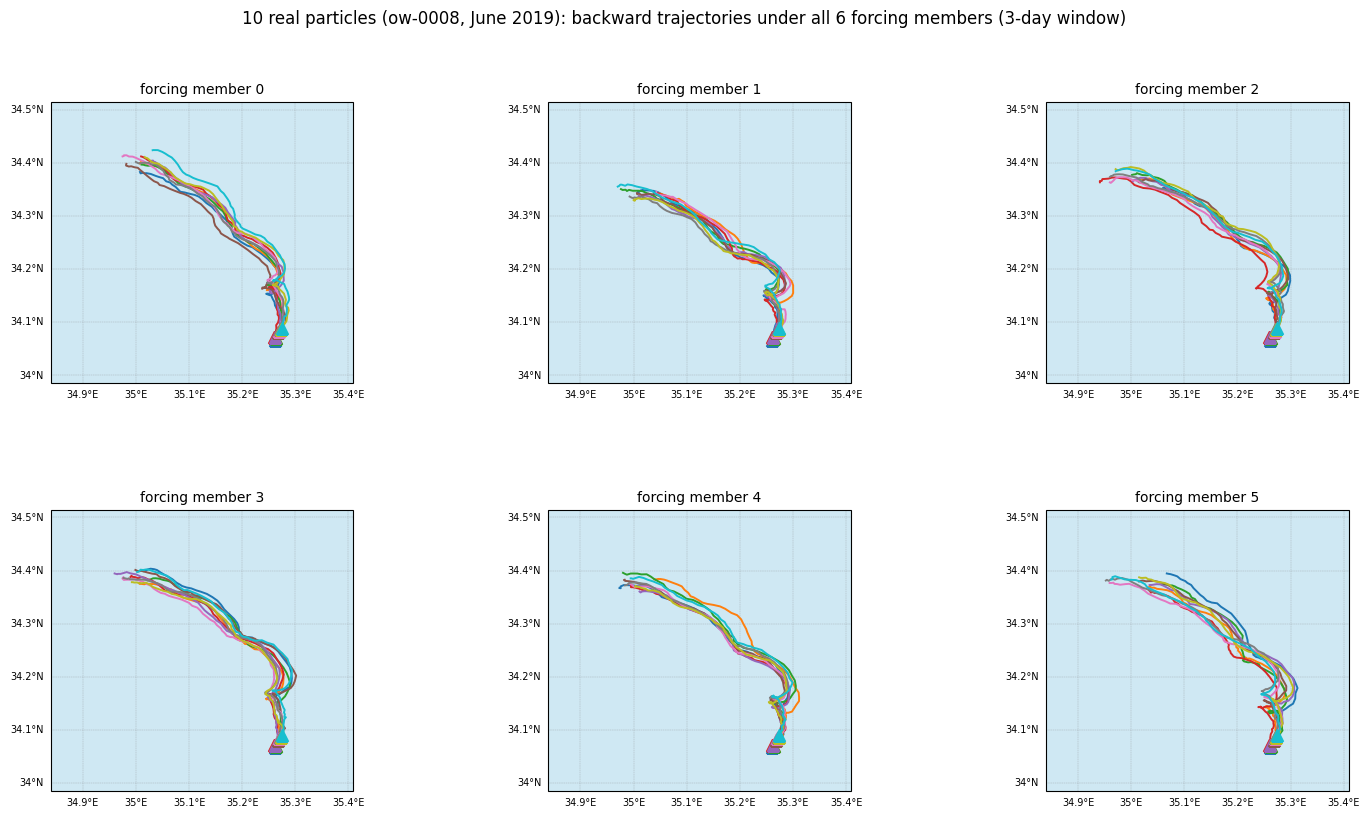

In [7]:
FORCING_MEMBER_IDS_USED = (0, 1, 2, 3, 4, 5)
traj_multi = {pid: {} for pid in selected_10}
for pid in selected_10:
    for m in FORCING_MEMBER_IDS_USED:
        mask = (records.particle_id == pid) & (records.forcing_member_id == m)
        order = np.argsort(-records.timestamp[mask].astype("int64"))
        traj_multi[pid][m] = dict(lat=records.lat[mask][order], lon=records.lon[mask][order], t=records.timestamp[mask][order])

n_members = len(FORCING_MEMBER_IDS_USED)
ncols = 3
nrows = int(np.ceil(n_members / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.2 * nrows), subplot_kw={"projection": MAP_PROJECTION})
axes = np.atleast_1d(axes).ravel()
for ax, m in zip(axes, FORCING_MEMBER_IDS_USED):
    add_geographic_basemap(ax, ANIMATION_EXTENT)
    for pid, c in zip(selected_10, colors):
        tr = traj_multi[pid][m]
        ax.plot(tr["lon"], tr["lat"], "-", color=c, linewidth=1.4, transform=ccrs.PlateCarree(), zorder=5)
        ax.plot(tr["lon"][0], tr["lat"][0], "^", color=c, markersize=9, transform=ccrs.PlateCarree(), zorder=6)
    ax.set_title(f"forcing member {m}", fontsize=10)
for ax in axes[len(FORCING_MEMBER_IDS_USED):]:
    ax.axis("off")
fig.suptitle(f"{n_select} real particles (ow-0008, June 2019): backward trajectories under all {n_members} forcing members (3-day window)", fontsize=12)
# explicit spacing instead of tight_layout -- cartopy GeoAxes are only partially compatible with
# tight_layout's automatic sizing, which produced overlapping row titles for this event's wider extent
fig.subplots_adjust(top=0.87, bottom=0.05, left=0.04, right=0.98, hspace=0.45, wspace=0.2)
save_with_retry(lambda: fig.savefig(os.path.join(OUTPUT_DIR, "07_multimember_static.png"), dpi=100), label="07_multimember_static.png")
plt.show()

## 7. `08_multimember_animation.mp4` (unchanged)

In [8]:
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows), subplot_kw={"projection": MAP_PROJECTION})
axes = np.atleast_1d(axes).ravel()
# explicit spacing BEFORE the colorbar is created -- fig.colorbar(ax=list(axes)) shrinks
# those axes to make its own room; calling subplots_adjust AFTER that (as an earlier version
# of this cell did) re-expands the grid back over the colorbar's space and overlaps it
fig.subplots_adjust(top=0.87, bottom=0.05, left=0.04, right=0.98, hspace=0.45, wspace=0.2)

lines_by_member = {}
points_by_member = {}
heatmap_by_member = {}
_initial_grid_mm = support_grids_by_t_s[float(checkpoints[-1])]
for ax, m in zip(axes, FORCING_MEMBER_IDS_USED):
    add_geographic_basemap(ax, ANIMATION_EXTENT)
    heatmap_by_member[m] = ax.pcolormesh(support_lon_grid, support_lat_grid, _initial_grid_mm, shading="auto", cmap="viridis", norm=display_norm(), transform=ccrs.PlateCarree(), zorder=3, alpha=0.85)
    ax.set_title(f"forcing member {m}", fontsize=10)
    lines_by_member[m] = [ax.plot([], [], "-", color=c, linewidth=1.4, transform=ccrs.PlateCarree(), zorder=5)[0] for c in colors]
    points_by_member[m] = [ax.plot([], [], "o", color=c, markersize=8, transform=ccrs.PlateCarree(), zorder=6)[0] for c in colors]
for ax in axes[len(FORCING_MEMBER_IDS_USED):]:
    ax.axis("off")
cb = fig.colorbar(heatmap_by_member[FORCING_MEMBER_IDS_USED[0]], ax=list(axes[:len(FORCING_MEMBER_IDS_USED)]), shrink=0.6, pad=0.02)
cb.set_label(DISPLAY_NORM_COLORBAR_LABEL, fontsize=6.5)
suptitle_mm = fig.suptitle("", fontsize=13)

def init_mm():
    artists = []
    for m in FORCING_MEMBER_IDS_USED:
        for l, p in zip(lines_by_member[m], points_by_member[m]):
            l.set_data([], []); p.set_data([], [])
            artists += [l, p]
        artists.append(heatmap_by_member[m])
    return artists

def update_mm(frame):
    artists = []
    t_now = traj_multi[selected_10[0]][FORCING_MEMBER_IDS_USED[0]]["t"][frame]
    grid_now = support_grids_by_t_s[float(np.datetime64(t_now, "ns"))]
    for m in FORCING_MEMBER_IDS_USED:
        for i, pid in enumerate(selected_10):
            tr = traj_multi[pid][m]
            lines_by_member[m][i].set_data(tr["lon"][:frame + 1], tr["lat"][:frame + 1])
            points_by_member[m][i].set_data([tr["lon"][frame]], [tr["lat"][frame]])
        heatmap_by_member[m].set_array(grid_now.ravel())
        artists += lines_by_member[m] + points_by_member[m] + [heatmap_by_member[m]]
    suptitle_mm.set_text(f"{n_select} real particles (ow-0008, June 2019) backward under {n_members} forcing members -- t = {np.datetime64(t_now,'ns')}")
    return artists

n_frames = len(checkpoints)
anim_mm = animation.FuncAnimation(fig, update_mm, frames=n_frames, init_func=init_mm, blit=False, interval=200)
mp4_path_mm = os.path.join(OUTPUT_DIR, "08_multimember_animation.mp4")
gif_path_mm = os.path.join(OUTPUT_DIR, "08_multimember_animation.gif")
save_animation_with_retry(anim_mm, mp4_path_mm, gif_path_mm, fps=6)
plt.close(fig)

saved animation (MP4) to C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\output\ow-0008\08_multimember_animation.mp4


## 8. `04_hotspot_heatmap.png` (T0/T36/T48/T72 snapshots, unchanged)

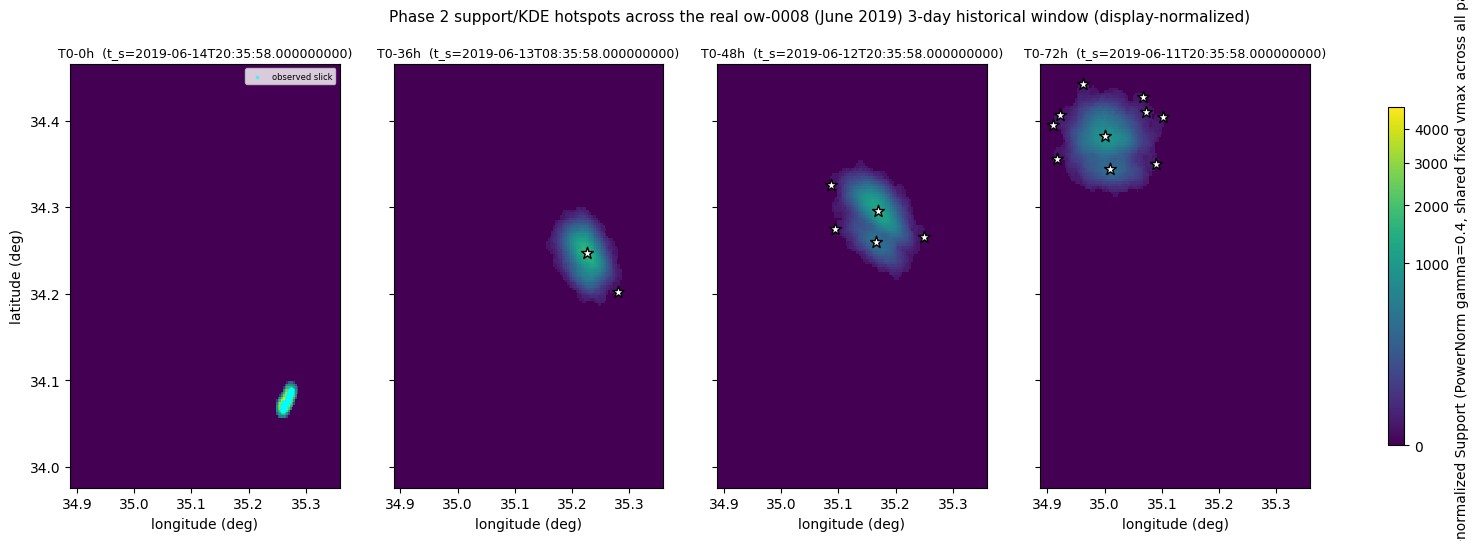

In [9]:
snapshot_hours = [0, 36, 48, 72]
snapshot_t_s = [T_OBS - np.timedelta64(h, "h") for h in snapshot_hours]

fig, axes = plt.subplots(1, 4, figsize=(20, 5.5), sharex=True, sharey=True)
top10_ids_preview = {c.candidate_id for c in sorted(all_candidates, key=lambda c: -c.support_score)[:10]}
for ax, h, t_s in zip(axes, snapshot_hours, snapshot_t_s):
    grid_vals = support_grids_by_t_s[float(t_s)]
    mesh = ax.pcolormesh(support_lon_grid, support_lat_grid, grid_vals, shading="auto", cmap="viridis", norm=display_norm())
    cands_here = [c for c in all_candidates if np.datetime64(c.t_s, "ns") == np.datetime64(t_s, "ns")]
    for c in cands_here:
        is_top10 = c.candidate_id in top10_ids_preview
        ax.scatter([c.x_peak], [c.y_peak], marker="*", s=180 if is_top10 else 80,
                   c="red" if is_top10 else "white", edgecolors="black", linewidths=1, zorder=5)
    if h == 0:
        ax.scatter(obs_lon, obs_lat, s=3, c="cyan", alpha=0.5, zorder=4, label="observed slick")
        ax.legend(fontsize=6, loc="upper right")
    ax.set_title(f"T0-{h}h  (t_s={np.datetime64(t_s,'ns')})", fontsize=9)
    ax.set_xlabel("longitude (deg)")
axes[0].set_ylabel("latitude (deg)")
fig.colorbar(mesh, ax=axes, label=DISPLAY_NORM_COLORBAR_LABEL, shrink=0.8)
fig.suptitle("Phase 2 support/KDE hotspots across the real ow-0008 (June 2019) 3-day historical window (display-normalized)", fontsize=11)
save_with_retry(lambda: fig.savefig(os.path.join(OUTPUT_DIR, "04_hotspot_heatmap.png"), dpi=100), label="04_hotspot_heatmap.png")
plt.show()

## 9. `AIS_tracks_map.png` (unchanged, using ow-0008's own AIS-2 event-window tracks)

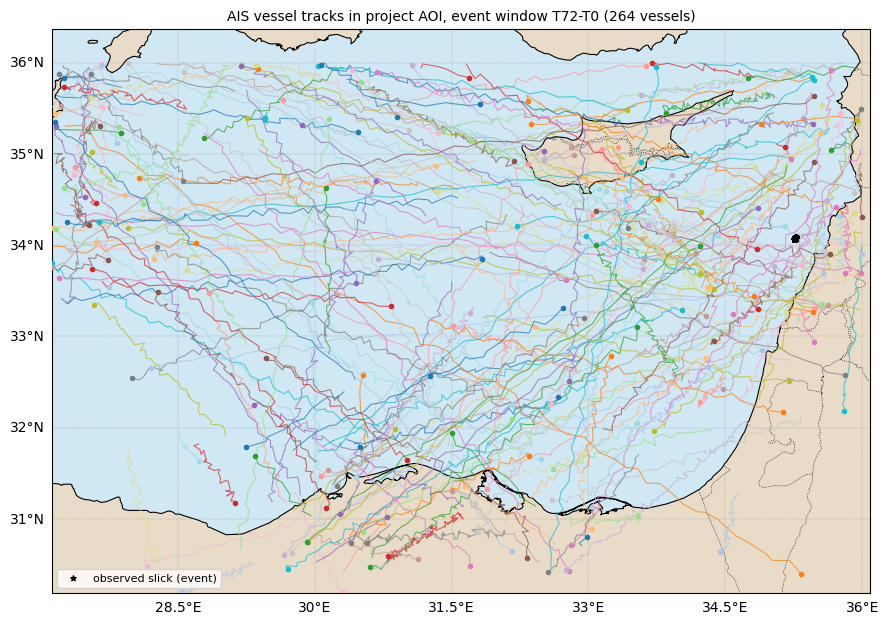

In [10]:
ais_track_df = pd.read_csv(os.path.join(RESULT_DIR, "AIS_vessel_tracks_event_window.csv"))
ais_track_df["timestamp"] = pd.to_datetime(ais_track_df["timestamp"], utc=True)
vessel_mmsis = ais_track_df["mmsi"].unique()

fig, ax = plt.subplots(figsize=(9, 8), subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent([AOI_WEST, AOI_EAST, AOI_SOUTH, AOI_NORTH], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.NaturalEarthFeature("physical", "ocean", "10m", facecolor="#cfe8f3"), zorder=0)
ax.add_feature(cfeature.NaturalEarthFeature("physical", "land", "10m", facecolor="#e8dcc8"), zorder=1)
ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.8, zorder=2)
ax.add_feature(cfeature.BORDERS.with_scale("10m"), linewidth=0.5, linestyle=":", zorder=2)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.6, linestyle="--")
gl.top_labels = False; gl.right_labels = False

cmap = plt.cm.tab20
for i, mmsi in enumerate(vessel_mmsis):
    vt = ais_track_df[ais_track_df["mmsi"] == mmsi].sort_values("timestamp")
    c = cmap(i % 20)
    ax.plot(vt["lon"], vt["lat"], "-", color=c, linewidth=0.8, alpha=0.7, transform=ccrs.PlateCarree(), zorder=4)
    ax.plot(vt["lon"].iloc[-1], vt["lat"].iloc[-1], "o", color=c, markersize=3, transform=ccrs.PlateCarree(), zorder=5)

ax.scatter(obs_lon, obs_lat, s=15, c="black", marker="*", transform=ccrs.PlateCarree(), zorder=6, label="observed slick (event)")
ax.set_title(f"AIS vessel tracks in project AOI, event window T72-T0 ({len(vessel_mmsis)} vessels)", fontsize=10)
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
save_with_retry(lambda: fig.savefig(os.path.join(OUTPUT_DIR, "AIS_tracks_map.png"), dpi=110), label="AIS_tracks_map.png")
plt.show()

## 10. Validation

In [11]:
expected_files = ["04_hotspot_heatmap.png", "07_multimember_static.png", "AIS_tracks_map.png", "validation_map_alignment.png"]
expected_files += ["08_multimember_animation.mp4"] if os.path.exists(os.path.join(OUTPUT_DIR, "08_multimember_animation.mp4")) else ["08_multimember_animation.gif"]
checks = []
for fn in expected_files:
    checks.append((f"{fn} saved", os.path.exists(os.path.join(OUTPUT_DIR, fn))))
for label, ok in checks:
    print(f"[{'OK' if ok else 'FAIL'}] {label}")
assert all(ok for _, ok in checks)

print()
output_files = sorted(os.listdir(OUTPUT_DIR))
print(f"{len(output_files)} files now saved under {OUTPUT_DIR}:")
for fn in output_files:
    size_kb = os.path.getsize(os.path.join(OUTPUT_DIR, fn)) / 1024
    print(f"  {fn}  ({size_kb:.1f} KB)")

[OK] 04_hotspot_heatmap.png saved
[OK] 07_multimember_static.png saved
[OK] AIS_tracks_map.png saved
[OK] validation_map_alignment.png saved
[OK] 08_multimember_animation.mp4 saved

15 files now saved under C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\output\ow-0008:
  04_hotspot_heatmap.png  (70.3 KB)
  07_multimember_static.png  (146.1 KB)
  08_multimember_animation.mp4  (264.7 KB)
  AIS_top15_evidence_summary.csv  (4.6 KB)
  AIS_top15_tracks.png  (274.8 KB)
  AIS_top15_vessels.csv  (7.5 KB)
  AIS_tracks_map.png  (609.5 KB)
  FINAL_RESEARCH_SUMMARY.txt  (6.3 KB)
  RUN_VALIDATION.txt  (0.9 KB)
  possible_source_origins.csv  (59.0 KB)
  possible_source_origins_ais_attribution.png  (116.2 KB)
  possible_source_origins_top.csv  (8.3 KB)
  potential_source_region_timeline.png  (107.4 KB)
  source_origin_summary.txt  (2.9 KB)
  validation_map_alignment.png  (75.7 KB)
